# From-Scratch CNN Ablation: BatchNorm x Data Augmentation

**Reid Sendroff**

I compared the original CNN and the BatchNorm CNN, both with and without augmentation. I kept the split, optimizer, learning rate, epochs, and test set the same for all four runs.

In [1]:
from pathlib import Path
import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 0.001
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.9.1+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5080


### Flower dataset

I used the same stratified 70% training, 15% validation, and 15% test split for all four models. Augmentation was only used on training images.

In [2]:
flower_root = DATA_DIR / "flower_photos"
if not flower_root.exists():
    download_and_extract_archive(
        "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
        download_root=str(DATA_DIR),
    )

catalog = datasets.ImageFolder(flower_root)
class_names = catalog.classes
records = [(Path(path), label) for path, label in catalog.samples]
labels = [label for _, label in records]
# use the same split for all four runs
train_records, remaining = train_test_split(
    records, test_size=0.30, random_state=SEED, stratify=labels
)
val_records, test_records = train_test_split(
    remaining,
    test_size=0.50,
    random_state=SEED,
    stratify=[label for _, label in remaining],
)

assert {p for p, _ in train_records}.isdisjoint({p for p, _ in val_records})
assert {p for p, _ in train_records}.isdisjoint({p for p, _ in test_records})
assert {p for p, _ in val_records}.isdisjoint({p for p, _ in test_records})
print("Class mapping:", catalog.class_to_idx)
print("Train/validation/test:", len(train_records), len(val_records), len(test_records))

Class mapping: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}
Train/validation/test: 2569 550 551


In [3]:
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
augmented_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
])

class PhotoDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(path) as image:
            return self.transform(image.convert("RGB")), label


val_dataset = PhotoDataset(val_records, image_transform)
test_dataset = PhotoDataset(test_records, image_transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


def make_train_loader(use_augmentation):
    transform = augmented_transform if use_augmentation else image_transform
    dataset = PhotoDataset(train_records, transform)
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )


images, targets = next(iter(make_train_loader(False)))
print("Batch shapes:", tuple(images.shape), tuple(targets.shape))
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

Batch shapes:

 (64, 3, 64, 64) (64,)


### CNN models

The shapes are `[N,3,64,64] -> [N,16,32,32] -> [N,32,16,16] -> [N,64,8,8]`. After flattening, each image has 4096 features. The output has shape `[N,5]`, with one logit for each flower class.

For the second model, I added `BatchNorm2d` after each convolution and before ReLU.

In [4]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes, use_batch_norm=False):
        super().__init__()

        def block(in_channels, out_channels):
            layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
            # add BatchNorm after Conv2d for the new model
            if use_batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
            return layers

        self.features = nn.Sequential(
            *block(3, 16),
            *block(16, 32),
            *block(32, 64),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * (IMAGE_SIZE // 8) ** 2, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


for use_batch_norm in (False, True):
    check_model = BasicCNN(len(class_names), use_batch_norm).to(device)
    with torch.inference_mode():
        output = check_model(images.to(device))
    print("Batch norm:", use_batch_norm, "output:", tuple(output.shape))
    assert output.shape == (len(images), len(class_names))
del check_model

Batch norm: False output: (64, 5)
Batch norm: True output: (64, 5)


### Training and testing

I selected the best epoch using validation loss. I then calculated accuracy and macro precision on all 551 test images.

In [5]:
criterion = nn.CrossEntropyLoss()


def evaluate(model, loader, include_predictions=False):
    model.eval()
    loss_sum = 0.0
    correct = 0
    count = 0
    all_labels = []
    all_predictions = []
    with torch.inference_mode():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(inputs)
            predictions = logits.argmax(dim=1)
            loss_sum += criterion(logits, labels).item() * labels.size(0)
            correct += (predictions == labels).sum().item()
            count += labels.size(0)
            if include_predictions:
                all_labels.extend(labels.cpu().tolist())
                all_predictions.extend(predictions.cpu().tolist())
    result = {"loss": loss_sum / count, "accuracy": correct / count}
    if include_predictions:
        result["macro_precision"] = precision_score(
            all_labels, all_predictions, average="macro", zero_division=0
        )
        result["examples"] = count
    return result


def run_experiment(use_batch_norm, use_augmentation):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    train_loader = make_train_loader(use_augmentation)
    model = BasicCNN(len(class_names), use_batch_norm).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_val_loss = float("inf")
    best_state = None
    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        correct = 0
        count = 0
        for inputs, labels in train_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += labels.size(0)

        train_metrics = {"loss": loss_sum / count, "accuracy": correct / count}
        val_metrics = evaluate(model, val_loader)
        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        # keep the weights with the lowest validation loss
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"epoch {epoch:02d}/{EPOCHS}: "
            f"train acc {train_metrics['accuracy']:.1%}, "
            f"val acc {val_metrics['accuracy']:.1%}"
        )

    model.load_state_dict(best_state)
    test_metrics = evaluate(model, test_loader, include_predictions=True)
    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "test": test_metrics,
    }


experiments = {}
start = time.perf_counter()
for use_batch_norm in (False, True):
    for use_augmentation in (False, True):
        name = (
            ("BatchNorm" if use_batch_norm else "Original")
            + " + "
            + ("augmentation" if use_augmentation else "no augmentation")
        )
        print("\n===", name, "===")
        experiments[name] = run_experiment(use_batch_norm, use_augmentation)
print(f"\nTotal training time: {(time.perf_counter() - start) / 60:.1f} minutes")


=== Original + no augmentation ===


epoch 01/15: train acc 33.4%, val acc 45.1%


epoch 02/15: train acc 48.8%, val acc 56.0%


epoch 03/15: train acc 55.1%, val acc 52.7%


epoch 04/15: train acc 56.7%, val acc 60.0%


epoch 05/15: train acc 61.7%, val acc 59.6%


... (55 outputs left out)

epoch 13/15: train acc 74.3%, val acc 72.2%


epoch 14/15: train acc 75.4%, val acc 69.3%


epoch 15/15: train acc 76.4%, val acc 70.2%



Total training time: 3.7 minutes


,model,selected_epoch,test_examples,test_accuracy,test_macro_precision
0,BatchNorm + augmentation,13,551,74.41%,75.92%
1,BatchNorm + no augmentation,9,551,71.32%,71.94%
2,Original + augmentation,14,551,67.88%,68.30%
3,Original + no augmentation,11,551,65.70%,65.41%


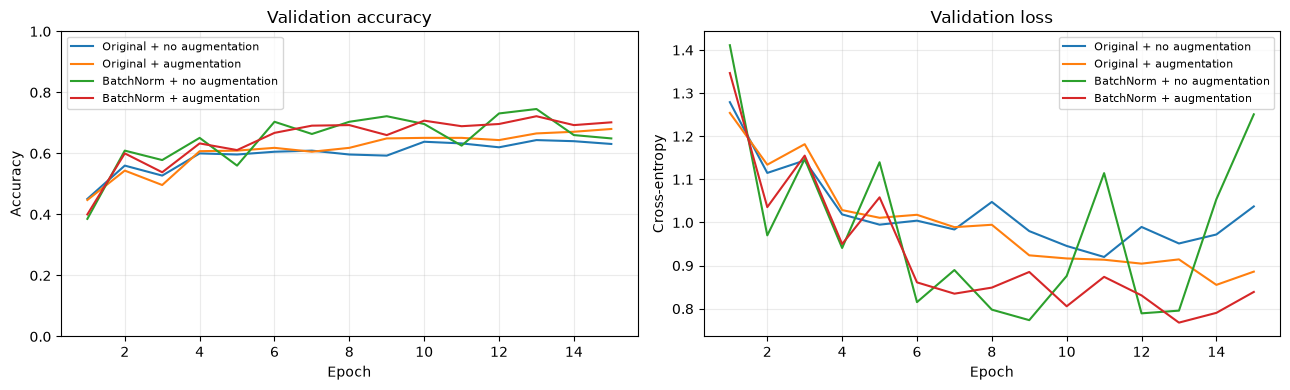

Best test accuracy was 74.41% for BatchNorm + augmentation. Without augmentation, adding BatchNorm changed test accuracy from 65.70% to 71.32%.
Because training is stochastic and this is one split, these numbers compare these controlled runs; they do not prove that either technique always helps.


In [6]:
rows = []
for name, result in experiments.items():
    rows.append({
        "model": name,
        "selected_epoch": result["best_epoch"],
        "test_examples": result["test"]["examples"],
        "test_accuracy": result["test"]["accuracy"],
        "test_macro_precision": result["test"]["macro_precision"],
    })
comparison = pd.DataFrame(rows).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
display(comparison.style.format({
    "test_accuracy": "{:.2%}",
    "test_macro_precision": "{:.2%}",
}))
assert (comparison["test_examples"] == len(test_dataset)).all()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, result in experiments.items():
    epochs = np.arange(1, EPOCHS + 1)
    axes[0].plot(epochs, result["history"]["val_accuracy"], label=name)
    axes[1].plot(epochs, result["history"]["val_loss"], label=name)
axes[0].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
axes[1].set(title="Validation loss", xlabel="Epoch", ylabel="Cross-entropy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

best = comparison.iloc[0]
original_plain = comparison.loc[comparison["model"] == "Original + no augmentation"].iloc[0]
bn_plain = comparison.loc[comparison["model"] == "BatchNorm + no augmentation"].iloc[0]
print(
    f"Best test accuracy was {best.test_accuracy:.2%} for {best.model}. "
    f"Without augmentation, adding BatchNorm changed test accuracy from "
    f"{original_plain.test_accuracy:.2%} to {bn_plain.test_accuracy:.2%}."
)
print(
    "Because training is stochastic and this is one split, these numbers compare "
    "these controlled runs; they do not prove that either technique always helps."
)

### Results

All four models were tested on the same 551 test images (values from the output above).

| Model | Selected epoch | Test accuracy | Macro precision |
|---|---:|---:|---:|
| Original, no augmentation | 11 | 65.70% | 65.41% |
| Original, augmentation | 14 | 67.88% | 68.30% |
| BatchNorm, no augmentation | 9 | 71.32% | 71.94% |
| BatchNorm, augmentation | 13 | **74.41%** | **75.92%** |

Augmentation improved the original CNN by 2.18 percentage points. BatchNorm without augmentation improved it by 5.62 points. The model using both had the highest accuracy, 8.71 points above the original model.

The BatchNorm model without augmentation started to overfit: by epoch 15 its training accuracy was 92.2% while validation accuracy was 64.9%, and its validation loss rose sharply after epoch 13. Keeping the epoch with the lowest validation loss avoided using those final weights.